<a href="https://colab.research.google.com/github/Melonangie/Galaxy-Vision/blob/main/baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Galaxy-Vision · Línea base (baseline) para clasificar galaxias MaNGA por T-type

**¿Qué es una línea base?** Es el modelo de referencia más simple, reproducible y honesto contra el que se mide cualquier mejora.
Sin línea base no sabemos si un 0.76 de balanced accuracy es mucho o poco.

Construimos una **escalera de complejidad** con las features de `FEatures.ipynb`:

| Nivel | Modelo | Pregunta que responde |
|---|---|---|
| 0 | Azar (`DummyClassifier`) | ¿Cuál es el piso? |
| 1 | **Corte físico en UNA feature** (D4000n, HδA, EW(Hα)…) | ¿Cuánto explica una sola propiedad física (la bimodalidad)? |
| 2 | Regresión logística multinomial | ¿Basta con fronteras lineales? |
| 3 | **GMM-Bayes** (astroML) | ¿Las clases son "nubes" gaussianas en el espacio físico? |
| 4–5 | Random Forest (top-10 y todas) | Referencia no lineal usada en `FEatures` |
| 6 | HistGradientBoosting | ¿Ayuda tratar los NaN como información (galaxias sin líneas)? |
| 7 | **Regresión ordinal de T** | ¿Conviene tratar T como número ordenado? |

Además estimamos el **techo** que impone el ruido de las etiquetas humanas. Luego medimos **qué información** usa la línea base
(ablación: catálogo frente a espectro), analizamos sus **errores con criterio astrofísico** y entregamos una **ficha** del
baseline final.

# 1. Marco teórico

## 1.1 La morfología y su relación con las propiedades físicas
La secuencia de Hubble (Hubble 1926, 1936; Sandage 1961) y su extensión de de Vaucouleurs (1959; RC3, de Vaucouleurs et al. 1991)
ordenan las galaxias según:
* la importancia del bulbo;
* el enrollamiento de los brazos;
* su resolución en regiones H II (Buta 2013).

A lo largo de la secuencia cambian de forma sistemática:
* la edad estelar;
* la tasa de formación estelar específica;
* el gas;
* la masa;
* la densidad superficial de masa;
* la dispersión de velocidades.

(Roberts & Haynes 1994; Kennicutt 1998; Kauffmann et al. 2003a,b; Blanton & Moustakas 2009.)

Por eso el espectro integrado contiene información morfológica, aunque **indirecta**.

## 1.2 Separadores clásicos de un solo parámetro (inspiran el nivel 1)
| Separador | Corte típico | Separa | Referencia |
|---|---|---|---|
| Color u − r | 2.22 | tempranas / tardías | Strateva et al. 2001 |
| Concentración R90/R50 | 2.6 | tempranas / tardías | Shimasaku et al. 2001 |
| Índice de Sérsic n | 2.5 | esferoides / discos | Shen et al. 2003 |
| D4000n | ≈ 1.5 | poblaciones viejas / jóvenes | Kauffmann et al. 2003a |
| EW(Hα) | 3 Å | pasivas o retiradas / con formación | Cid Fernandes et al. 2011 |

Estos cortes funcionan por la **bimodalidad** de galaxias (secuencia roja y nube azul; Strateva et al. 2001; Baldry et al. 2004),
pero fallan con:
* **espirales rojas** (Masters et al. 2010a);
* **elípticas azules** (Schawinski et al. 2009);
* **S0**, que son viejas como las E pero son discos (van den Bergh 1976; Cappellari et al. 2011).

## 1.3 Clasificación automática de la morfología: antecedentes
* **Imágenes:** redes neuronales que igualan el acuerdo entre expertos (Lahav et al. 1995; Naim et al. 1995), SVM (Huertas-Company
  et al. 2011) y CNN (Domínguez Sánchez et al. 2018, 2022). Catálogos visuales masivos: Galaxy Zoo (Lintott et al. 2008, 2011) y
  Nair & Abraham (2010).
* **Espectros:** PCA (Connolly et al. 1995; Yip et al. 2004) y clasificación no supervisada (Sánchez Almeida et al. 2010).
* **MaNGA:** catálogo visual (Vázquez-Mata et al. 2022) y profundo (Domínguez Sánchez et al. 2022).

**Límite intrínseco:** dos expertos difieren en ≈ 1.8 T rms (Naim et al. 1995; Lahav et al. 1995). Ningún modelo puede "acertar"
más de lo que los humanos coinciden entre sí.

## 1.4 Resultados de `FEatures.ipynb` que usamos como punto de partida
* Muestra limpia: **9885 galaxias** (7413 de train y 2472 de test), 13 T-types de E a Im.
* RF en test, con el top-10 de features:
  * balanced accuracy **0.307** (detallado), **0.762** (tres clases) y **0.561** (intervalos);
  * κ cuadrático ≈ 0.84 en los esquemas ordinales.
* Features del top-10 en los tres esquemas: D4000n_syn, HdA, PC1, b_a, log_EW_Ha, log_NII_Ha y log_Sigma90.

In [8]:
!pip install -q astroML imbalanced-learn

In [9]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display

# --- Astronomía ---
from astropy.table import Table                        # resultados en ECSV (admite texto con acentos y metadatos)
from astropy.visualization import hist as hist_astro   # histogramas con bins de Knuth
from astroML.stats import sigmaG                       # σ robusta = 0.7413·IQR
from astroML.resample import bootstrap                 # remuestreo para intervalos de confianza
from astroML.classification import GMMBayes            # Bayes con una mezcla de gaussianas por clase

# --- Estadística y aprendizaje automático ---
from scipy.stats import spearmanr
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.model_selection import StratifiedKFold, cross_val_predict, learning_curve
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (balanced_accuracy_score, f1_score, cohen_kappa_score, recall_score,
                             ConfusionMatrixDisplay)
from imblearn.pipeline import Pipeline                 # pipeline que admite SMOTE (solo actúa al entrenar)
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
SEMILLA = 42                                           # la misma semilla que en FEatures

In [10]:
from google.colab import drive
drive.mount('/content/drive')

RUTA_RES  = '/content/drive/MyDrive/Proyecto_morfologia/features_results'   # la misma carpeta que FEatures
RUTA_BASE = os.path.join(RUTA_RES, 'baseline')                              # resultados de este notebook
os.makedirs(RUTA_BASE, exist_ok=True)

df = pd.read_csv(os.path.join(RUTA_RES, 'dataset_features.csv'), index_col=0)   # índice = plate-ifu
with open(os.path.join(RUTA_RES, 'metadatos_features.json')) as f:
    meta = json.load(f)
FEATURES, FAMILIAS, TOP10 = meta['FEATURES'], meta['FAMILIAS'], meta['TOP10']
MEJOR_BALANCEO, ORDEN_CLASES = meta['MEJOR_BALANCEO'], meta['ORDEN_CLASES']

ESPECTROS = np.load(os.path.join(RUTA_RES, 'espectros_dataset.npy'))   # fila i = galaxia i de df
GRID = np.load(os.path.join(RUTA_RES, 'grid.npy'))                     # λ en reposo [Å]

es_train = (df['split'] == 'train').values
idx_train, idx_test = df.index[es_train], df.index[~es_train]
print(df.shape, '|', len(idx_train), 'train |', len(idx_test), 'test |', len(FEATURES), 'features')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(9885, 154) | 7413 train | 2472 test | 51 features


In [11]:
# Los mismos esquemas de clases que en FEatures, sección 8
ESQUEMAS = ['detallado', 'tres_clases', 'intervalos']
NOMBRE_TTYPE = {-5: 'E', -2: 'S0', 0: 'S0a', 1: 'Sa', 2: 'Sab', 3: 'Sb', 4: 'Sbc', 5: 'Sc',
                6: 'Scd', 7: 'Sd', 8: 'Sdm', 9: 'Sm', 10: 'Im'}

def esquema_tres(t):
    return 'Temprana' if t <= 0 else ('Intermedia' if t <= 4 else 'Tardía')

def esquema_intervalos(t):
    if t == -5: return 'E'
    if t <= 0:  return 'S0–S0a'
    if t <= 2:  return 'Sa–Sab'
    if t <= 4:  return 'Sb–Sbc'
    if t <= 7:  return 'Sc–Sd'
    return 'Sdm–Im'

CONVERTIR = {'detallado': NOMBRE_TTYPE.get, 'tres_clases': esquema_tres, 'intervalos': esquema_intervalos}
T_VALIDOS = np.array(sorted(df['Ttype'].unique()))       # T-types presentes (-5, -2, 0, 1 … 10)

def a_t_valido(t_continuo):
    """Lleva cada T continuo al T-type válido más cercano (p. ej. -3.4 -> -2)."""
    t = np.asarray(t_continuo, dtype=float)[:, None]
    return T_VALIDOS[np.abs(t - T_VALIDOS[None, :]).argmin(axis=1)]

# T representativo de cada clase (mediana en train): permite medir el error en unidades de T
T_REP = {e: df[es_train].groupby(f'y_{e}')['Ttype'].median().to_dict() for e in ESQUEMAS}

# Comprobación de coherencia: las etiquetas exportadas coinciden con estas funciones
for e in ESQUEMAS:
    assert (df['Ttype'].apply(CONVERTIR[e]) == df[f'y_{e}']).all(), e

for e in ESQUEMAS:
    display(pd.crosstab(df['split'], df[f'y_{e}'])[ORDEN_CLASES[e]])

y_detallado,E,S0,S0a,Sa,Sab,Sb,Sbc,Sc,Scd,Sd,Sdm,Sm,Im
split,,,,,,,,,,,,,
test,444,324,152,269,261,277,254,253,112,85,19,19,3
train,1330,970,458,808,782,830,762,759,338,255,57,56,8


y_tres_clases,Temprana,Intermedia,Tardía
split,,,
test,920,1061,491
train,2758,3182,1473


y_intervalos,E,S0–S0a,Sa–Sab,Sb–Sbc,Sc–Sd,Sdm–Im
split,,,,,,
test,444,476,530,531,450,41
train,1330,1428,1590,1592,1352,121


**Conclusión 3:**
* Deberías ver 7413 galaxias de train y 2472 de test, con las mismas proporciones por clase.
* En el esquema detallado el desbalance es extremo: E ≈ 1330 frente a Im ≈ 8 en train, unas 166 veces.
* **Im (T = 10) tiene unas 3 galaxias en test.** Su recall en test es casi una moneda al aire, así que cualquier métrica
  "macro" del esquema detallado tendrá mucha varianza. Por eso añadimos intervalos de confianza por bootstrap (sección 12).

# 4. Protocolo de evaluación
* **Validación cruzada estratificada de 5 pliegues, solo con train,** para comparar y elegir modelos.
* **El test se usa una sola vez,** al final (sección 12).
* Métricas, las mismas de `FEatures`:
  * **balanced accuracy (BA):** el recall medio por clase; no premia a la clase mayoritaria (Brodersen et al. 2010);
  * **F1 macro;**
  * **κ cuadrático** (Cohen 1968): penaliza más los errores lejanos, adecuado porque T es **ordinal**;
  * **acierto ±1 clase;**
  * **MAE en unidades de T.**

In [12]:
def metricas(y_true, y_pred, esquema, t_real):
    """Métricas nominales y ordinales. t_real = T-type verdadero (para el MAE en unidades de T)."""
    pos = {cl: i for i, cl in enumerate(ORDEN_CLASES[esquema])}
    i_t = np.array([pos[cl] for cl in y_true]); i_p = np.array([pos[cl] for cl in y_pred])
    t_pred = np.array([T_REP[esquema][cl] for cl in y_pred])
    ba = balanced_accuracy_score(y_true, y_pred)
    K = len(ORDEN_CLASES[esquema])
    return {'balanced_acc': ba,
            'mejora_sobre_azar': (ba - 1 / K) / (1 - 1 / K),    # 0 = azar, 1 = perfecto (comparable entre esquemas)
            'F1_macro': f1_score(y_true, y_pred, average='macro'),
            'kappa_cuadratico': cohen_kappa_score(i_t, i_p, weights='quadratic'),
            'acierto_±1_clase': np.mean(np.abs(i_t - i_p) <= 1),
            'MAE_T': np.mean(np.abs(np.asarray(t_real) - t_pred))}

def hacer_modelo(estrategia, n_arboles=300):
    """Pipeline de FEatures: imputar -> estandarizar -> [balancear] -> Random Forest (Breiman 2001)."""
    pasos = [('imputar', SimpleImputer(strategy='median')), ('escalar', StandardScaler())]
    if estrategia == 'submuestreo':
        pasos.append(('balancear', RandomUnderSampler(random_state=SEMILLA)))
    if estrategia == 'smote':
        pasos.append(('balancear', SMOTE(k_neighbors=3, random_state=SEMILLA)))   # Chawla et al. 2002
    peso = 'balanced' if estrategia == 'class_weight' else None
    pasos.append(('modelo', RandomForestClassifier(n_estimators=n_arboles, min_samples_leaf=2, class_weight=peso,
                                                   n_jobs=-1, random_state=SEMILLA)))
    return Pipeline(pasos)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
RESULTADOS_CV, PRED_CV = {}, {}                          # diccionarios: volver a ejecutar no duplica filas

def registrar_cv(nombre, esquema, pred, n_features):
    y = df.loc[es_train, f'y_{esquema}']
    PRED_CV[(nombre, esquema)] = np.asarray(pred)
    RESULTADOS_CV[(nombre, esquema)] = {'modelo': nombre, 'esquema': esquema, 'n_features': n_features,
                                        **metricas(y, pred, esquema, df.loc[es_train, 'Ttype'])}

def evaluar_cv(nombre, modelo, columnas, esquema):
    """Predicciones fuera de pliegue en train y registro de las métricas."""
    np.random.seed(SEMILLA)                              # GMMBayes usa el generador global de numpy
    pred = cross_val_predict(modelo, df.loc[es_train, columnas], df.loc[es_train, f'y_{esquema}'], cv=cv)
    registrar_cv(nombre, esquema, pred, len(columnas))

def tabla_cv():
    return pd.DataFrame(RESULTADOS_CV.values()).round(3)

## 4.1 El techo: ¿cuánto se puede acertar si las etiquetas tienen ruido?
Dos expertos difieren en ≈ 1.8 T rms (Naim et al. 1995). Si cada uno tiene un error independiente, el error de **un** clasificador
respecto a la "verdad" es ≈ 1.8/√2 ≈ **1.3 T**.

Simulamos lo siguiente:
1. Partimos de la etiqueta del catálogo.
2. Le sumamos ruido gaussiano de σ T, como haría "otro experto".
3. Medimos cuánto coincide con la original.

Esa coincidencia es la BA de un **modelo perfecto** evaluado contra etiquetas ruidosas: un **techo aproximado**.

In [13]:
rng = np.random.default_rng(SEMILLA)
t_train = df.loc[es_train, 'Ttype'].values
filas = []
for sigma in [0.5, 1.0, 1.3, 1.8]:
    # Un "segundo experto" simulado: el T del catálogo más ruido gaussiano, llevado al T válido más cercano
    t_ruidoso = a_t_valido(t_train + rng.normal(0, sigma, len(t_train)))
    for e in ESQUEMAS:
        y_real  = [CONVERTIR[e](t) for t in t_train]
        y_ruido = [CONVERTIR[e](t) for t in t_ruidoso]
        filas.append({'sigma_T': sigma, 'esquema': e, 'BA_techo': balanced_accuracy_score(y_real, y_ruido)})

TECHO = pd.DataFrame(filas).pivot(index='sigma_T', columns='esquema', values='BA_techo').round(3)
display(TECHO)

esquema,detallado,intervalos,tres_clases
sigma_T,,,
0.5,0.756,0.896,0.939
1.0,0.490,0.771,0.860
1.3,0.405,0.695,0.829
1.8,0.330,0.593,0.767


**Conclusión 4.1 (verifícalo con tus resultados):**
* Con σ = 1.3 T, un T se queda en su propia clase solo si el ruido es < 0.5 T, con probabilidad ≈ 30 %. Por tanto, el
  **techo del esquema detallado debería rondar 0.3–0.4**.
* El RF de `FEatures` obtuvo **0.307**, así que probablemente está **muy cerca del límite que imponen las etiquetas**. El problema no
  es el modelo: los T-types vecinos no se distinguen ni siquiera entre expertos.
* El techo de **tres clases** es mucho más alto (≈ 0.8), porque hace falta un error grande para cruzar una frontera.
* Primera lección del baseline: **la resolución morfológica que pedimos debe ser compatible con la precisión de las etiquetas**
  (Naim et al. 1995; Lintott et al. 2008).

# 5. Nivel 0: el azar
* `most_frequent` siempre predice la clase mayoritaria, con BA = 1/K exacto.
* `stratified` predice al azar con las proporciones de train.

Cualquier modelo útil debe superar ambos con claridad.

In [14]:
for e in ESQUEMAS:
    for estrategia in ['most_frequent', 'stratified']:
        evaluar_cv(f'0 Azar ({estrategia})', DummyClassifier(strategy=estrategia, random_state=SEMILLA), TOP10[e], e)
display(tabla_cv())

,modelo,esquema,n_features,balanced_acc,mejora_sobre_azar,F1_macro,kappa_cuadratico,acierto_±1_clase,MAE_T
0,0 Azar (most_frequent),detallado,10,0.077,0.000,0.023,0.000,0.310,6.075
1,0 Azar (stratified),detallado,10,0.072,-0.005,0.072,-0.015,0.290,4.273
2,0 Azar (most_frequent),tres_clases,10,0.333,0.000,0.200,0.000,1.000,3.272
3,0 Azar (stratified),tres_clases,10,0.338,0.007,0.338,-0.020,0.845,3.827
4,0 Azar (most_frequent),intervalos,10,0.167,0.000,0.059,0.000,0.612,3.272
5,0 Azar (stratified),intervalos,10,0.172,0.006,0.172,0.008,0.521,4.169


**Conclusión 5:**
* El azar da BA = 1/13 ≈ 0.077 (detallado), 0.333 (tres clases) y 0.167 (intervalos).
* κ ≈ 0: la predicción constante no captura ningún orden.
* `most_frequent` consigue un "acierto ±1" engañosamente alto en intervalos, porque la clase central es la más poblada. Por eso
  **nunca usamos accuracy simple**.

# 6. Nivel 1: un corte físico en UNA sola feature
Imita los separadores clásicos (Strateva et al. 2001; Kauffmann et al. 2003a), con dos pasos:
1. Se ordenan las galaxias por una sola propiedad. El signo lo da la correlación de Spearman con el orden de las clases.
2. Se corta en los cuantiles que reproducen la fracción de cada clase en train. Si el 30 % son Tempranas, el 30 % "más viejo" se
   etiqueta Temprana.

Es un clasificador **ordinal de un parámetro**: totalmente interpretable y con 0 hiperparámetros.

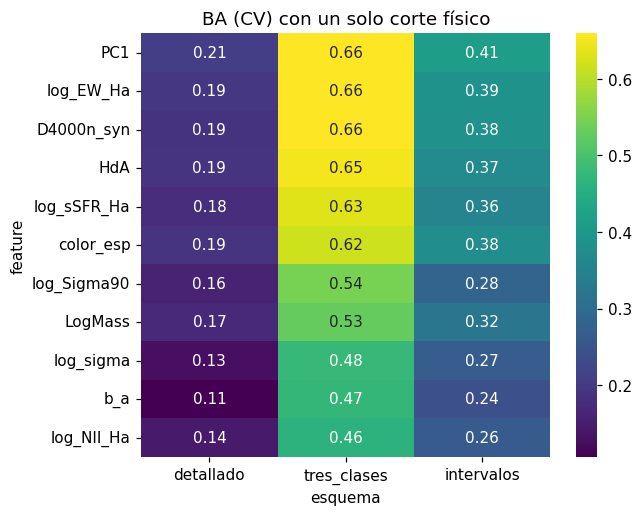

Mejor feature individual: {'detallado': 'PC1', 'tres_clases': 'PC1', 'intervalos': 'PC1'}


In [15]:
class CorteFisico(BaseEstimator, ClassifierMixin):
    """Clasificador de una feature: umbrales sobre x que respetan las fracciones de clase de train."""
    def __init__(self, orden=None):
        self.orden = orden                                   # clases de la más temprana a la más tardía

    def fit(self, X, y):
        x = np.asarray(X, dtype=float).ravel()
        y = np.asarray(y)
        self.mediana_ = np.nanmedian(x)
        x = np.where(np.isnan(x), self.mediana_, x)          # NaN -> mediana de train
        rango = np.array([list(self.orden).index(c) for c in y])
        self.signo_ = 1.0 if spearmanr(x, rango).correlation >= 0 else -1.0   # p. ej. D4000n disminuye hacia tardías
        fraccion_acumulada = np.cumsum([np.mean(y == c) for c in self.orden])[:-1]
        self.umbrales_ = np.quantile(self.signo_ * x, fraccion_acumulada)
        self.classes_ = np.unique(y)
        return self

    def predict(self, X):
        x = np.asarray(X, dtype=float).ravel()
        x = np.where(np.isnan(x), self.mediana_, x)
        return np.array(self.orden)[np.searchsorted(self.umbrales_, self.signo_ * x, side='right')]

CANDIDATAS_1D = [c for c in ['D4000n_syn', 'HdA', 'log_EW_Ha', 'PC1', 'color_esp', 'log_sSFR_Ha', 'log_NII_Ha',
                             'log_Sigma90', 'log_sigma', 'LogMass', 'b_a'] if c in df.columns]
filas = []
for e in ESQUEMAS:
    y = df.loc[es_train, f'y_{e}']
    for c in CANDIDATAS_1D:
        pred = cross_val_predict(CorteFisico(orden=ORDEN_CLASES[e]), df.loc[es_train, [c]], y, cv=cv)
        filas.append({'feature': c, 'esquema': e, 'BA': balanced_accuracy_score(y, pred)})

BA_1D = pd.DataFrame(filas).pivot(index='feature', columns='esquema', values='BA')[ESQUEMAS]
BA_1D = BA_1D.sort_values('tres_clases', ascending=False)
plt.figure(figsize=(6, 5))
sns.heatmap(BA_1D, annot=True, fmt='.2f', cmap='viridis')
plt.title('BA (CV) con un solo corte físico'); plt.show()

MEJOR_1D = BA_1D.idxmax().to_dict()                      # la mejor feature individual de cada esquema
print('Mejor feature individual:', MEJOR_1D)
for e in ESQUEMAS:
    evaluar_cv('1 Corte 1D', CorteFisico(orden=ORDEN_CLASES[e]), [MEJOR_1D[e]], e)

**Conclusión 6 (esperada):**
* Las mejores features individuales deberían ser las de **edad estelar y formación estelar**: HδA, D4000n_syn y log EW(Hα). Son las
  mismas que lideraron el ε² univariado de `FEatures` (≈ 0.50).
* En **tres clases**, un solo corte debería dar BA ≈ 0.6–0.7, una gran parte de lo que logra el RF.
* La morfología gruesa es, en gran medida, **la bimodalidad edad / formación estelar** (Kauffmann et al. 2003a; Baldry et al. 2004).
* `b_a` sola es mala en general, aunque fue clave para E vs S0 en `FEatures`. Su información es **geométrica** y solo sirve en
  combinación.
* Elegir la mejor feature con la misma CV es ligeramente optimista; con 11 candidatas el sesgo es pequeño.

## 6.1 ¿Recuperamos el corte clásico D4000n ≈ 1.5?
Kauffmann et al. (2003a) muestran que la distribución de D4000n es **bimodal**, con el mínimo en ≈ 1.5.
Comparamos ese valor con los umbrales que aprende `CorteFisico` en el esquema de tres clases. Usamos histogramas con **bins de
Knuth** (astropy), que eligen el ancho de bin de forma bayesiana en lugar de a ojo.

Umbrales aprendidos de D4000n (Tardía|Intermedia, Intermedia|Temprana): [1.242 1.603]


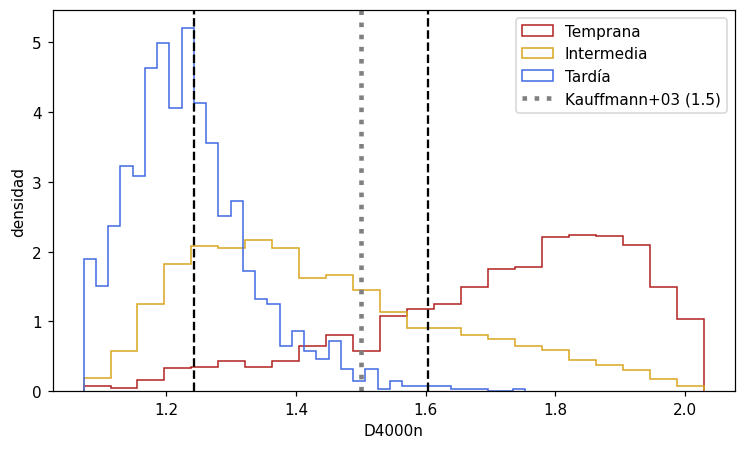

,viejo
y_tres_clases,
Temprana,0.84
Intermedia,0.34
Tardía,0.02


In [16]:
corte_d4 = CorteFisico(orden=ORDEN_CLASES['tres_clases']).fit(df.loc[es_train, ['D4000n']],
                                                             df.loc[es_train, 'y_tres_clases'])
umbrales_d4 = np.sort(corte_d4.signo_ * corte_d4.umbrales_)          # volver a unidades de D4000n
print('Umbrales aprendidos de D4000n (Tardía|Intermedia, Intermedia|Temprana):', umbrales_d4.round(3))

fig, ax = plt.subplots(figsize=(8, 4.5))
for clase, color in zip(ORDEN_CLASES['tres_clases'], ['firebrick', 'goldenrod', 'royalblue']):
    x = df.loc[es_train & (df['y_tres_clases'] == clase), 'D4000n'].dropna()
    hist_astro(x, bins='knuth', ax=ax, histtype='step', lw=2, density=True, color=color, label=clase)
for u in umbrales_d4:
    ax.axvline(u, color='k', ls='--')
ax.axvline(1.5, color='gray', ls=':', lw=3, label='Kauffmann+03 (1.5)')
ax.set_xlabel('D4000n'); ax.set_ylabel('densidad'); ax.legend(); plt.show()

# ¿Qué fracción de cada clase queda por encima de 1.5 ("población vieja")?
display((df[es_train].assign(viejo=df['D4000n'] > 1.5)
         .groupby('y_tres_clases')['viejo'].mean().reindex(ORDEN_CLASES['tres_clases']).round(2)))

**Conclusión 6.1:**
* El umbral **Intermedia | Temprana** debería caer cerca de **1.5–1.6**: el algoritmo redescubre el corte de Kauffmann et al.
  (2003a) sin que se lo digamos.
* La mayoría de Tempranas están por encima de 1.5 y la mayoría de Tardías por debajo. Las **Intermedias se reparten a ambos lados**:
  - las Sa–Sab tienen bulbos viejos (D4000n alto);
  - las Sb–Sbc tienen discos con formación estelar.

  Las espirales tempranas son la población de **transición** (el "valle verde"; Schawinski et al. 2014).
* Las distribuciones se solapan mucho: un corte en D4000n separa **edad**, no **estructura**.

# 7. Nivel 2: modelos lineales y generativos
* **Regresión logística multinomial** (`class_weight='balanced'`): fronteras lineales en el espacio estandarizado.
* **GMM-Bayes** (astroML; Ivezić et al. 2014, §9.3):
  - modela cada clase como una **mezcla de 2 gaussianas** y clasifica con el teorema de Bayes;
  - las 2 componentes permiten, por ejemplo, que "Temprana" contenga un grupo de E y otro de S0;
  - usa como *prior* la frecuencia de cada clase, así que favorece a las clases grandes;
  - es un modelo **generativo**: si funciona bien, las clases son "nubes" compactas en el espacio físico.

In [17]:
def pipe_simple(modelo):
    """imputar -> estandarizar -> modelo (los modelos lineales y gaussianos necesitan escalas comparables)."""
    return Pipeline([('imputar', SimpleImputer(strategy='median')), ('escalar', StandardScaler()), ('modelo', modelo)])

for e in ESQUEMAS:
    evaluar_cv('2 Logística (top-10)', pipe_simple(LogisticRegression(max_iter=3000, class_weight='balanced')), TOP10[e], e)
    # GMMBayes: sin kwargs adicionales (sklearn.clone los perdería); la semilla global se fija en evaluar_cv
    evaluar_cv('3 GMM-Bayes (top-10)', pipe_simple(GMMBayes(n_components=2)), TOP10[e], e)
display(tabla_cv())

,modelo,esquema,n_features,balanced_acc,mejora_sobre_azar,F1_macro,kappa_cuadratico,acierto_±1_clase,MAE_T
0,0 Azar (most_frequent),detallado,10,0.077,0.000,0.023,0.000,0.310,6.075
1,0 Azar (stratified),detallado,10,0.072,-0.005,0.072,-0.015,0.290,4.273
2,0 Azar (most_frequent),tres_clases,10,0.333,0.000,0.200,0.000,1.000,3.272
3,0 Azar (stratified),tres_clases,10,0.338,0.007,0.338,-0.020,0.845,3.827
4,0 Azar (most_frequent),intervalos,10,0.167,0.000,0.059,0.000,0.612,3.272
5,0 Azar (stratified),intervalos,10,0.172,0.006,0.172,0.008,0.521,4.169
6,1 Corte 1D,detallado,1,0.207,0.141,0.202,0.724,0.600,2.115
7,1 Corte 1D,tres_clases,1,0.659,0.489,0.659,0.644,0.986,2.200
8,1 Corte 1D,intervalos,1,0.411,0.293,0.411,0.697,0.846,2.142
9,2 Logística (top-10),detallado,10,0.291,0.232,0.267,0.788,0.684,1.652


**Conclusión 7 (esperada):**
* La **logística balanceada** debería quedar cerca del RF en tres clases (BA ≈ 0.74–0.77). La separación
  Temprana / Intermedia / Tardía es **casi lineal** en el espacio edad–formación estelar–densidad.
* **GMM-Bayes** suele tener mejor κ que BA. Su *prior* empuja hacia las clases grandes (E, Sb, Sbc) y castiga a las raras (Sdm, Sm,
  Im), así que su BA detallada debería ser menor que la de la logística balanceada.
* Si GMM-Bayes queda cerca de la logística, las clases son nubes aproximadamente gaussianas: una descripción física compacta.

# 8. Nivel 3: modelos no lineales
* **RF top-10 y RF con todas las features:** el modelo de `FEatures`, con su mejor balanceo por esquema.
* **HistGradientBoosting** (Friedman 2001; Ke et al. 2017):
  - trata los **NaN de forma nativa**, sin imputar;
  - eso importa porque un NaN en [N II]/Hα o en EW(Hβ) suele significar "**no hay líneas de emisión**", que es información
    morfológica (79 % de las E y 64 % de las S0 son "Sin líneas" en el BPT de `FEatures`).

In [18]:
for e in ESQUEMAS:
    evaluar_cv('4 RF (top-10)', hacer_modelo(MEJOR_BALANCEO[e]), TOP10[e], e)
    evaluar_cv('5 RF (todas)',  hacer_modelo(MEJOR_BALANCEO[e]), FEATURES, e)
    hgb = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, class_weight='balanced',
                                         random_state=SEMILLA)                     # requiere scikit-learn ≥ 1.2
    evaluar_cv('6 HistGB (top-10, NaN nativos)', hgb, TOP10[e], e)
display(tabla_cv())

,modelo,esquema,n_features,balanced_acc,mejora_sobre_azar,F1_macro,kappa_cuadratico,acierto_±1_clase,MAE_T
0,0 Azar (most_frequent),detallado,10,0.077,0.000,0.023,0.000,0.310,6.075
1,0 Azar (stratified),detallado,10,0.072,-0.005,0.072,-0.015,0.290,4.273
2,0 Azar (most_frequent),tres_clases,10,0.333,0.000,0.200,0.000,1.000,3.272
3,0 Azar (stratified),tres_clases,10,0.338,0.007,0.338,-0.020,0.845,3.827
4,0 Azar (most_frequent),intervalos,10,0.167,0.000,0.059,0.000,0.612,3.272
5,0 Azar (stratified),intervalos,10,0.172,0.006,0.172,0.008,0.521,4.169
6,1 Corte 1D,detallado,1,0.207,0.141,0.202,0.724,0.600,2.115
7,1 Corte 1D,tres_clases,1,0.659,0.489,0.659,0.644,0.986,2.200
8,1 Corte 1D,intervalos,1,0.411,0.293,0.411,0.697,0.846,2.142
9,2 Logística (top-10),detallado,10,0.291,0.232,0.267,0.788,0.684,1.652


**Conclusión 8 (esperada):**
* El RF top-10 debería reproducir la CV de `FEatures`: BA ≈ 0.30 (detallado), ≈ 0.77 (tres clases) y ≈ 0.55 (intervalos).
* **RF con todas** apenas debería mejorar al top-10. Las 51 features son muy redundantes: hay grupos con |ρ| > 0.85.
* **HistGB** debería empatar o mejorar algo en los esquemas con clases pequeñas, gracias a `class_weight` y al uso de NaN como
  señal.
* Si la mejora no lineal sobre la logística es < 0.02–0.03, **la complejidad no compensa**. El cuello de botella es la información
  física, no el modelo.

# 9. Regresión ordinal: tratar T como un número
T es **ordinal**: confundir Sa con Sab es mucho menos grave que confundir Sa con Im.
Un clasificador ignora ese orden; una **regresión** lo usa de forma natural:
1. Se predice T continuo con HistGradientBoostingRegressor, con pesos balanceados para no ignorar las clases raras.
2. Se lleva al T válido más cercano.
3. Se convierte a cada esquema.

**Un solo modelo sirve para los tres esquemas.**

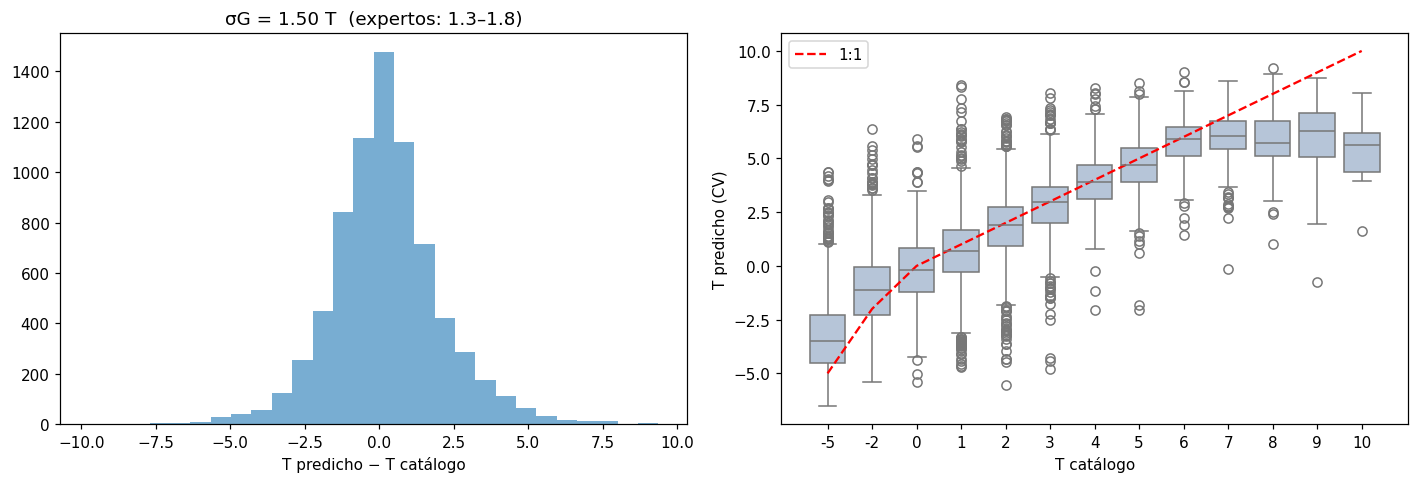

Mediana del residuo por T: {-5: 1.49, -2: 0.87, 0: -0.18, 1: -0.3, 2: -0.11, 3: -0.04, 4: -0.1, 5: -0.31, 6: -0.12, 7: -0.96, 8: -2.3, 9: -2.73, 10: -4.38}


In [19]:
cols_t = TOP10['detallado']
X_t = df.loc[es_train, cols_t]
t_real = df.loc[es_train, 'Ttype'].values
y_det = df.loc[es_train, 'y_detallado'].values
T_CV = np.zeros(len(t_real))                       # T continuo predicho fuera de pliegue

for i_ajuste, i_valid in cv.split(X_t, y_det):     # mismos pliegues estratificados que el resto
    reg = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=SEMILLA)
    reg.fit(X_t.iloc[i_ajuste], t_real[i_ajuste], sample_weight=compute_sample_weight('balanced', y_det[i_ajuste]))
    T_CV[i_valid] = reg.predict(X_t.iloc[i_valid])

T_CV_VALIDO = a_t_valido(T_CV)
for e in ESQUEMAS:
    registrar_cv('7 Regresión de T (HistGB)', e, [CONVERTIR[e](t) for t in T_CV_VALIDO], len(cols_t))

# Residuos: ¿cuánto se equivoca el modelo en unidades de T?
residuo = T_CV - t_real
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
hist_astro(residuo, bins='knuth', ax=axs[0], histtype='stepfilled', alpha=0.6)
axs[0].set_xlabel('T predicho − T catálogo')
axs[0].set_title(f'σG = {sigmaG(residuo):.2f} T  (expertos: 1.3–1.8)')
sns.boxplot(x=t_real, y=T_CV, ax=axs[1], color='lightsteelblue')
axs[1].plot(range(len(T_VALIDOS)), T_VALIDOS, 'r--', label='1:1')
axs[1].set_xlabel('T catálogo'); axs[1].set_ylabel('T predicho (CV)'); axs[1].legend()
plt.tight_layout(); plt.show()
print('Mediana del residuo por T:', pd.Series(residuo).groupby(t_real).median().round(2).to_dict())

**Conclusión 9 (esperada):**
* **σG** es una dispersión robusta (astroML; 0.7413 × IQR). Debería quedar en **≈ 1.5–2 T**, del mismo orden que la discrepancia
  entre expertos (1.3–1.8 T; Naim et al. 1995).
* En la caja por T verás **regresión a la media**: las E se predicen algo más tardías y las Sm/Im algo más tempranas. Es típico de
  la regresión con extremos poco poblados.
* La regresión suele dar **mejor κ cuadrático y MAE_T** y algo peor BA que los clasificadores: sacrifica aciertos exactos a cambio
  de errores más cercanos.
* Para morfología, donde T es continuo en la naturaleza (de Vaucouleurs 1959), es una alternativa muy natural.

# 10. Resumen de la validación cruzada
Comparamos todos los niveles con dos referencias: el **azar** (1/K) y el **techo** de ruido con σ = 1.3 T.

balanced_acc


esquema,detallado,tres_clases,intervalos
modelo,,,
0 Azar (most_frequent),0.077,0.333,0.167
0 Azar (stratified),0.072,0.338,0.172
1 Corte 1D,0.207,0.659,0.411
2 Logística (top-10),0.291,0.760,0.566
3 GMM-Bayes (top-10),0.268,0.734,0.493
4 RF (top-10),0.307,0.758,0.556
5 RF (todas),0.301,0.774,0.551
"6 HistGB (top-10, NaN nativos)",0.285,0.763,0.505
7 Regresión de T (HistGB),0.274,0.758,0.498


kappa_cuadratico


esquema,detallado,tres_clases,intervalos
modelo,,,
0 Azar (most_frequent),0.000,0.000,0.000
0 Azar (stratified),-0.015,-0.020,0.008
1 Corte 1D,0.724,0.644,0.697
2 Logística (top-10),0.788,0.763,0.810
3 GMM-Bayes (top-10),0.820,0.734,0.799
4 RF (top-10),0.837,0.770,0.834
5 RF (todas),0.842,0.789,0.839
"6 HistGB (top-10, NaN nativos)",0.848,0.769,0.830
7 Regresión de T (HistGB),0.866,0.779,0.842


MAE_T


esquema,detallado,tres_clases,intervalos
modelo,,,
0 Azar (most_frequent),6.075,3.272,3.272
0 Azar (stratified),4.273,3.827,4.169
1 Corte 1D,2.115,2.200,2.142
2 Logística (top-10),1.652,1.791,1.662
3 GMM-Bayes (top-10),1.560,1.885,1.607
4 RF (top-10),1.390,1.783,1.436
5 RF (todas),1.362,1.734,1.406
"6 HistGB (top-10, NaN nativos)",1.335,1.785,1.472
7 Regresión de T (HistGB),1.316,1.734,1.463


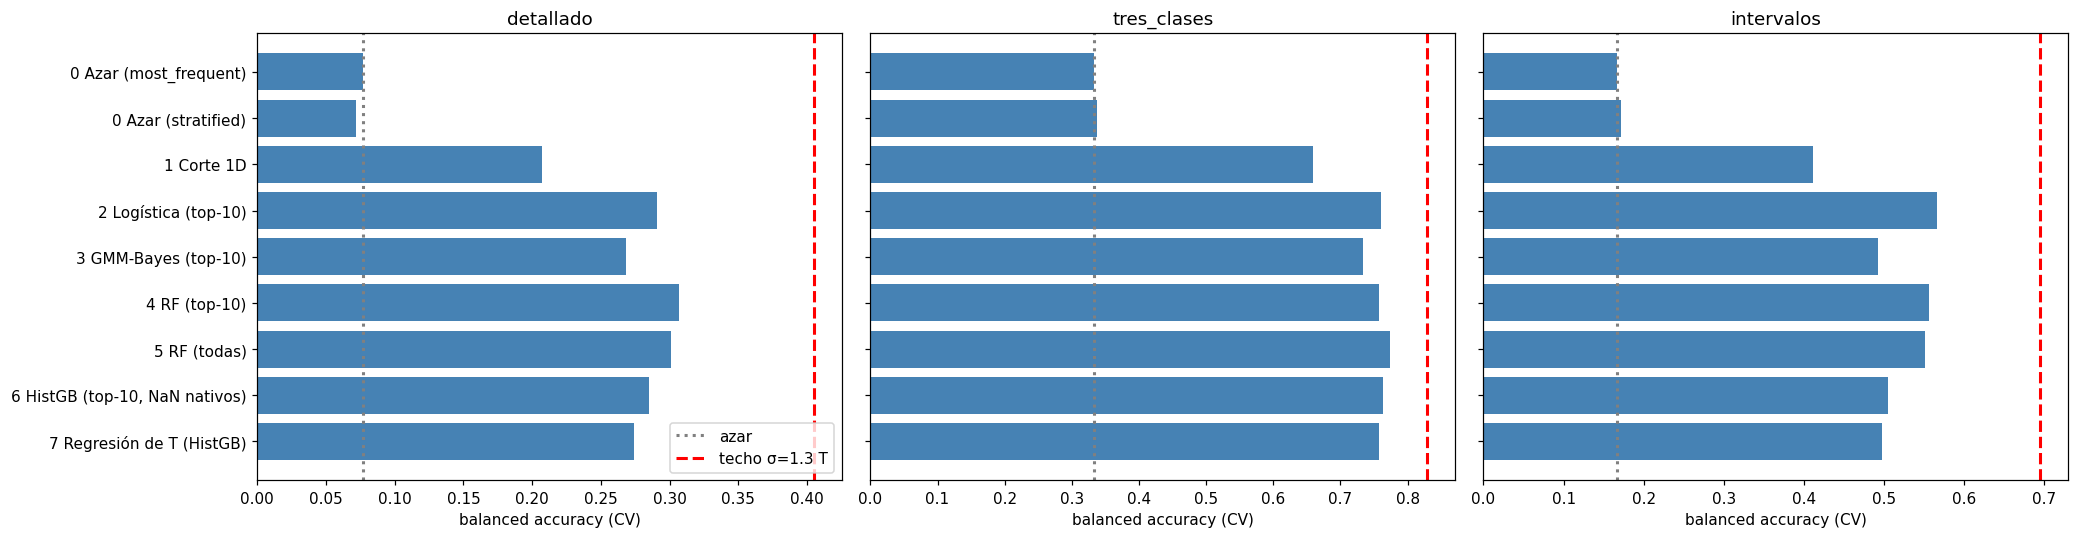

In [20]:
res = tabla_cv()
for metrica in ['balanced_acc', 'kappa_cuadratico', 'MAE_T']:
    print(metrica)
    display(res.pivot(index='modelo', columns='esquema', values=metrica)[ESQUEMAS])

fig, axs = plt.subplots(1, 3, figsize=(19, 5), sharey=True)
for ax, e in zip(axs, ESQUEMAS):
    r = res[res['esquema'] == e].sort_values('modelo')
    ax.barh(r['modelo'], r['balanced_acc'], color='steelblue')
    ax.axvline(1 / len(ORDEN_CLASES[e]), color='gray', ls=':', lw=2, label='azar')
    ax.axvline(TECHO.loc[1.3, e], color='red', ls='--', lw=2, label='techo σ=1.3 T')
    ax.set_title(e); ax.set_xlabel('balanced accuracy (CV)')
axs[0].invert_yaxis(); axs[0].legend(loc='lower right')
plt.tight_layout(); plt.show()
res.to_csv(os.path.join(RUTA_BASE, 'resultados_cv.csv'), index=False)

**Conclusión 10 (interpreta con tus números):**
* **Salto grande** de 0 → 1: una sola propiedad física (edad / formación estelar) captura la mayor parte de la señal en tres clases.
* **Salto medio** de 1 → 2: combinar edad, densidad de masa (Σ*), inclinación (b/a) y metalicidad / ionización ([N II]/Hα) añade
  información **estructural**.
* **Salto pequeño** de 2 → 3–7: la no linealidad aporta poco. Las features ya están bien diseñadas.
* Si los mejores modelos tocan la línea roja del techo, **no hay mucho más que ganar con estas etiquetas**. Para más detalle
  morfológico hace falta información **espacial** (imágenes o mapas IFU de MaNGA), no un modelo más complejo.

# 11. Ablación: ¿qué tipo de información usa el baseline?
Entrenamos el mismo RF con distintos **conjuntos de features**. Así medimos cuánto aporta cada fuente física:

| Conjunto | Contenido | Pregunta |
|---|---|---|
| Solo M* | LogMass | ¿La morfología es solo masa? (relación masa–morfología; Kauffmann et al. 2003b; Bundy et al. 2010) |
| Catálogo | M*, R90, Σ*, b/a | ¿Basta con la estructura fotométrica, sin espectro? |
| Espectro edad + SF | D4000n_syn, HδA, EW(Hα), PC1 | ¿Basta con la historia de formación estelar? |
| Espectro completo | todas, excepto las que dependen del catálogo NSA | ¿Cuánto sabe el espectro **por sí solo**? |
| Top-10 | consenso de `FEatures` | la referencia |
| Top-10 sin b/a | quita la inclinación | ¿Cuánto depende de la orientación? |
| Todas | 51 features | el máximo |

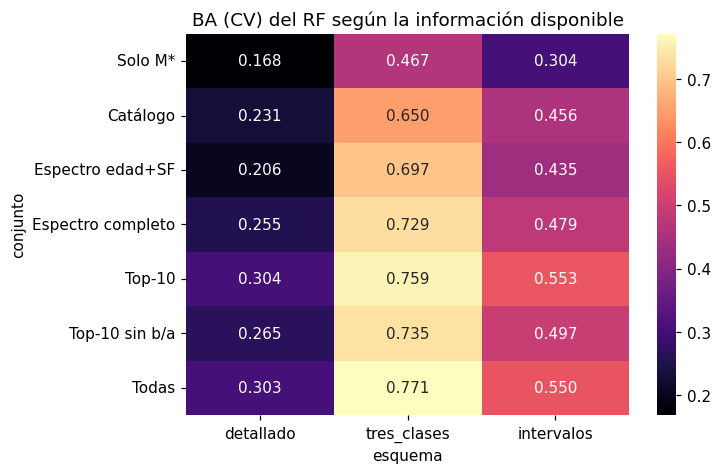

In [21]:
DEPENDEN_CATALOGO = ['LogMass', 'log_R90_kpc', 'log_Sigma90', 'b_a', 'log_sSFR_Ha']   # usan M*, radios o ejes del NSA

def existentes(cols):
    return [c for c in cols if c in df.columns]

ABLACION = []
for e in ESQUEMAS:
    conjuntos = {
        'Solo M*': existentes(['LogMass']),
        'Catálogo': existentes(['LogMass', 'log_R90_kpc', 'log_Sigma90', 'b_a']),
        'Espectro edad+SF': existentes(['D4000n_syn', 'HdA', 'log_EW_Ha', 'PC1']),
        'Espectro completo': [f for f in FEATURES if f not in DEPENDEN_CATALOGO],
        'Top-10': TOP10[e],
        'Top-10 sin b/a': [f for f in TOP10[e] if f != 'b_a'],
        'Todas': FEATURES}
    y = df.loc[es_train, f'y_{e}']
    for nombre, cols in conjuntos.items():
        pred = cross_val_predict(hacer_modelo(MEJOR_BALANCEO[e], n_arboles=200), df.loc[es_train, cols], y, cv=cv)
        ABLACION.append({'conjunto': nombre, 'esquema': e, 'n_features': len(cols),
                         'BA': balanced_accuracy_score(y, pred)})

ABLACION = pd.DataFrame(ABLACION)
tabla_abl = ABLACION.pivot(index='conjunto', columns='esquema', values='BA')[ESQUEMAS]
tabla_abl = tabla_abl.loc[list(conjuntos)]               # orden lógico de las filas
plt.figure(figsize=(6.5, 4.5))
sns.heatmap(tabla_abl, annot=True, fmt='.3f', cmap='magma')
plt.title('BA (CV) del RF según la información disponible'); plt.show()
ABLACION.to_csv(os.path.join(RUTA_BASE, 'ablacion.csv'), index=False)

**Conclusión 11 (esperada):**
* **Solo M\*** debería superar claramente al azar, sobre todo en tres clases: las galaxias masivas son mayoritariamente tempranas
  (Kauffmann et al. 2003b). Aun así, queda muy lejos del top-10.
* **Espectro edad + SF** (4 features) debería acercarse mucho al top-10 en tres clases. La división temprana / tardía es, sobre todo,
  **historia de formación estelar**.
* **Catálogo** debería ser competitivo en E vs S0. La forma proyectada (b/a) y la compacidad (Σ*) son información **estructural**
  que el espectro integrado no tiene (Cappellari et al. 2011; Emsellem et al. 2011).
* Si **Top-10 sin b/a** cae sobre todo en los esquemas detallado e intervalos, la inclinación es lo que permite separar E (redondas)
  de S0 (discos que pueden verse de canto). Es un recordatorio de que la clase **E vs S0 es geométrica, no espectral**
  (van den Bergh 1976).
* La diferencia entre **Espectro completo** y **Todas** mide lo que aporta el catálogo NSA por encima de la espectroscopía.

# 12. Curva de aprendizaje: ¿faltan datos?
Medimos la BA de validación al entrenar con fracciones crecientes de train:
* si la curva **sigue subiendo** al 100 %, más galaxias ayudarían (por ejemplo, un MaNGA DR17 completo o SDSS-IV + SAMI);
* si se **aplana**, el límite está en las features o en las etiquetas.

Usamos RF con `class_weight`, sin SMOTE, porque con subconjuntos pequeños las clases raras tienen menos de 4 galaxias y SMOTE falla.

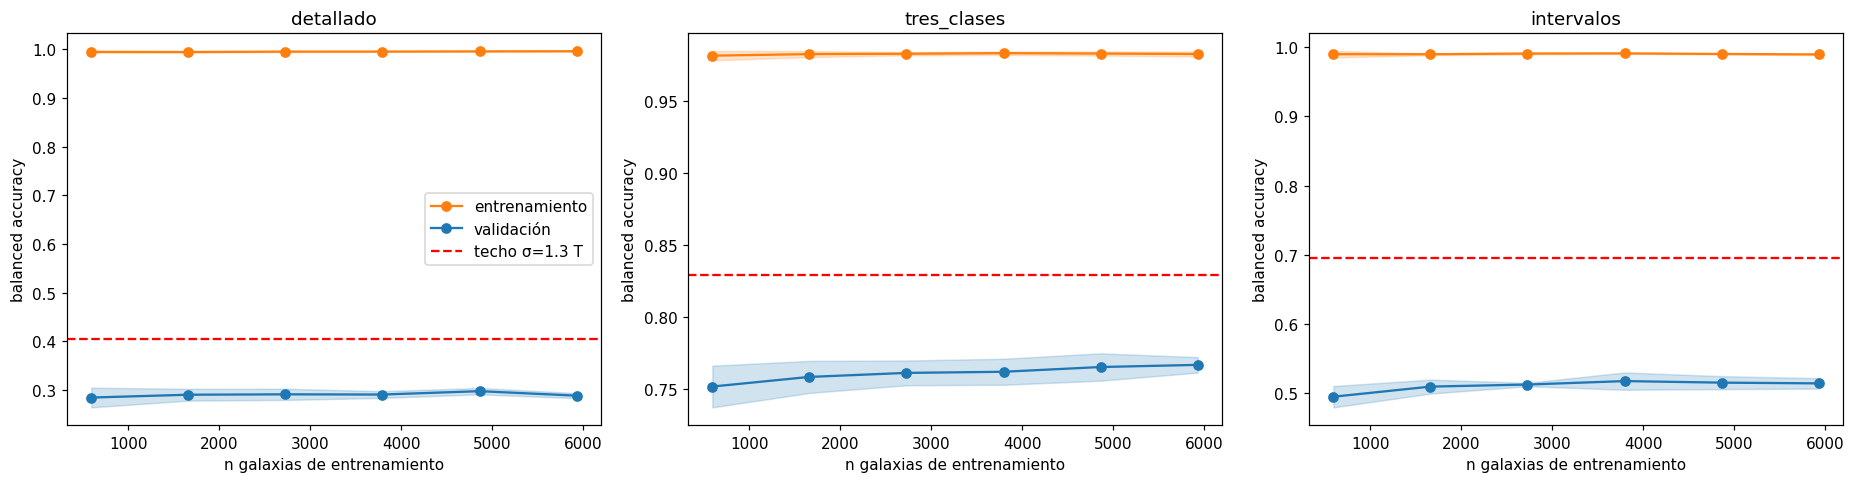

In [22]:
fig, axs = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, e in zip(axs, ESQUEMAS):
    tamanos, sc_train, sc_valid = learning_curve(
        hacer_modelo('class_weight', n_arboles=200), df.loc[es_train, TOP10[e]], df.loc[es_train, f'y_{e}'],
        train_sizes=np.linspace(0.1, 1.0, 6), cv=cv, scoring='balanced_accuracy',
        shuffle=True, random_state=SEMILLA, n_jobs=-1)
    for sc, color, etiqueta in [(sc_train, 'tab:orange', 'entrenamiento'), (sc_valid, 'tab:blue', 'validación')]:
        ax.plot(tamanos, sc.mean(axis=1), 'o-', color=color, label=etiqueta)
        ax.fill_between(tamanos, sc.mean(axis=1) - sc.std(axis=1), sc.mean(axis=1) + sc.std(axis=1),
                        color=color, alpha=0.2)
    ax.axhline(TECHO.loc[1.3, e], color='red', ls='--', label='techo σ=1.3 T')
    ax.set_title(e); ax.set_xlabel('n galaxias de entrenamiento'); ax.set_ylabel('balanced accuracy')
axs[0].legend(); plt.tight_layout(); plt.show()

**Conclusión 12 (esperada):**
* **Tres clases:** la validación debería aplanarse antes de las ~3000 galaxias. Más datos no ayudan; el límite es físico y de
  etiquetas.
* **Detallado:** puede seguir subiendo despacio por las clases raras (Sdm, Sm, Im, con menos de 100 galaxias). En estas clases, **más
  galaxias de tipo tardío** sí ayudarían.
* La gran distancia entre entrenamiento (≈ 1) y validación indica que el RF **memoriza**. Es esperable con árboles profundos y no es
  grave si la validación es estable.

# 13. Evaluación final en test (una sola vez)
1. Se reentrena cada modelo con **todo train** y se evalúa en las 2472 galaxias de test.
2. La incertidumbre de la BA se estima con **bootstrap** (Efron 1979) usando `astroML.resample.bootstrap`: 500 remuestreos del test
   y el intervalo del 95 % (percentiles 2.5 y 97.5).

   Es crucial en el esquema detallado, porque una clase con 3 galaxias (Im) puede mover la BA en ±0.03.

In [23]:
def construir_modelos(e):
    """Los mismos modelos de la CV (mismos nombres) con sus columnas, para el esquema e."""
    return {
        '0 Azar (most_frequent)': (DummyClassifier(strategy='most_frequent'), TOP10[e]),
        '0 Azar (stratified)':    (DummyClassifier(strategy='stratified', random_state=SEMILLA), TOP10[e]),
        '1 Corte 1D':             (CorteFisico(orden=ORDEN_CLASES[e]), [MEJOR_1D[e]]),
        '2 Logística (top-10)':   (pipe_simple(LogisticRegression(max_iter=3000, class_weight='balanced')), TOP10[e]),
        '3 GMM-Bayes (top-10)':   (pipe_simple(GMMBayes(n_components=2)), TOP10[e]),
        '4 RF (top-10)':          (hacer_modelo(MEJOR_BALANCEO[e]), TOP10[e]),
        '5 RF (todas)':           (hacer_modelo(MEJOR_BALANCEO[e]), FEATURES),
        '6 HistGB (top-10, NaN nativos)': (HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05,
                                           class_weight='balanced', random_state=SEMILLA), TOP10[e])}

def ic_bootstrap(y_true, y_pred, n_remuestreos=500):
    """IC 95 % de la balanced accuracy con astroML.bootstrap (remuestreo de galaxias de test)."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    def ba_por_fila(indices):                       # indices: matriz (n_remuestreos, n_test)
        return np.array([balanced_accuracy_score(y_true[i], y_pred[i]) for i in indices])
    distribucion = bootstrap(np.arange(len(y_true)), n_remuestreos, ba_por_fila,
                             pass_indices=True, random_state=SEMILLA)
    return np.percentile(distribucion, [2.5, 97.5])

RESULTADOS_TEST, PRED_TEST, MODELOS_FINALES = {}, {}, {}
t_test = df.loc[idx_test, 'Ttype']

def registrar_test(nombre, e, pred, n_features):
    y_te = df.loc[idx_test, f'y_{e}']
    bajo, alto = ic_bootstrap(y_te, pred)
    PRED_TEST[(nombre, e)] = np.asarray(pred)
    RESULTADOS_TEST[(nombre, e)] = {'modelo': nombre, 'esquema': e, 'n_features': n_features,
                                    **metricas(y_te, pred, e, t_test), 'BA_ic95_bajo': bajo, 'BA_ic95_alto': alto}

for e in ESQUEMAS:
    for nombre, (modelo, cols) in construir_modelos(e).items():
        np.random.seed(SEMILLA)
        modelo.fit(df.loc[idx_train, cols], df.loc[idx_train, f'y_{e}'])
        MODELOS_FINALES[(nombre, e)] = (modelo, cols)
        registrar_test(nombre, e, modelo.predict(df.loc[idx_test, cols]), len(cols))

# Regresión de T: un solo modelo, convertido a los tres esquemas
REG_T = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=SEMILLA)
REG_T.fit(df.loc[idx_train, cols_t], df.loc[idx_train, 'Ttype'],
          sample_weight=compute_sample_weight('balanced', df.loc[idx_train, 'y_detallado']))
T_TEST = REG_T.predict(df.loc[idx_test, cols_t])
T_TEST_VALIDO = a_t_valido(T_TEST)
for e in ESQUEMAS:
    registrar_test('7 Regresión de T (HistGB)', e, [CONVERTIR[e](t) for t in T_TEST_VALIDO], len(cols_t))

TEST = pd.DataFrame(RESULTADOS_TEST.values()).round(3)
display(TEST.pivot(index='modelo', columns='esquema', values='balanced_acc')[ESQUEMAS])

esquema,detallado,tres_clases,intervalos
modelo,,,
0 Azar (most_frequent),0.077,0.333,0.167
0 Azar (stratified),0.074,0.341,0.164
1 Corte 1D,0.225,0.657,0.400
2 Logística (top-10),0.277,0.760,0.561
3 GMM-Bayes (top-10),0.270,0.731,0.519
4 RF (top-10),0.309,0.763,0.564
5 RF (todas),0.300,0.774,0.567
"6 HistGB (top-10, NaN nativos)",0.283,0.764,0.530
7 Regresión de T (HistGB),0.293,0.765,0.527


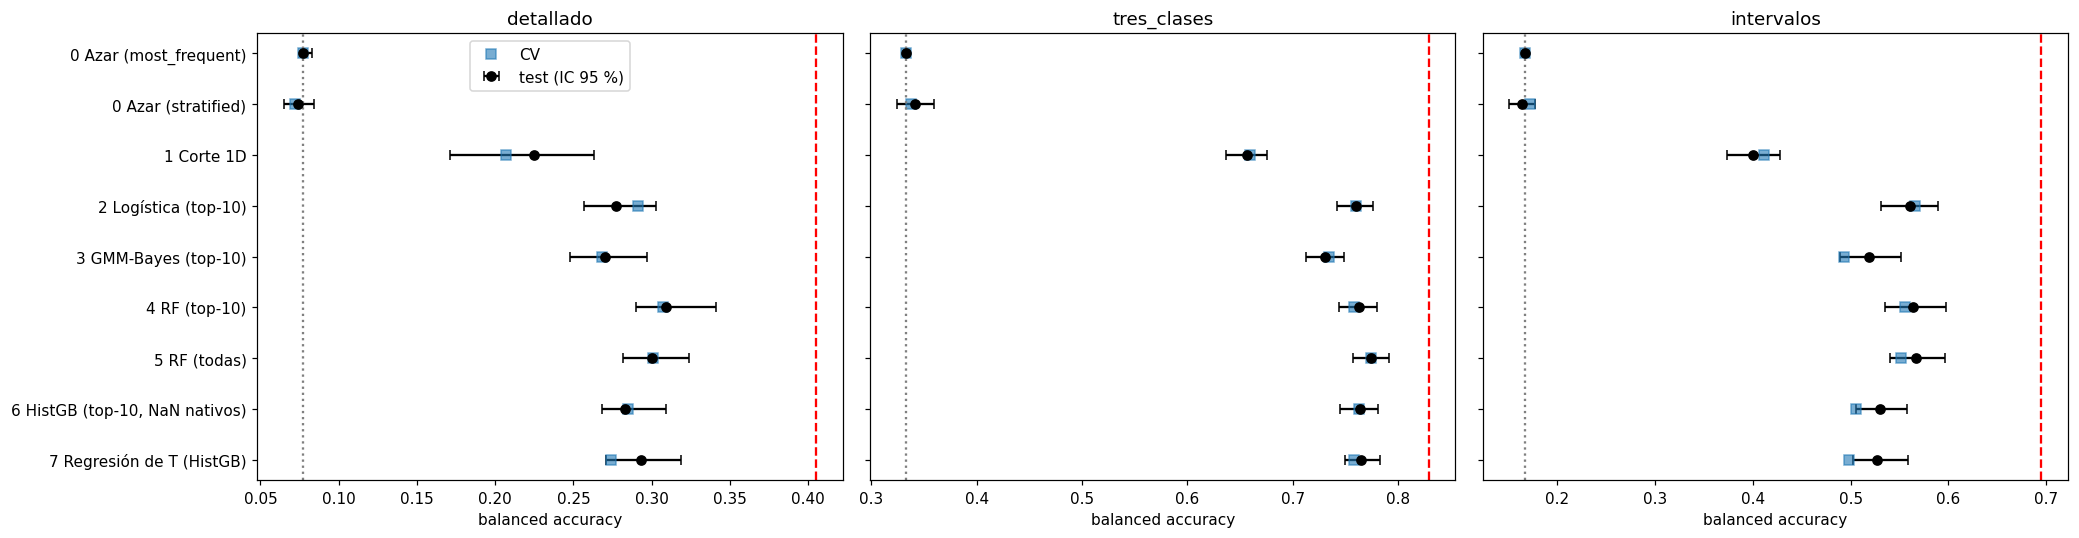

In [24]:
# CV vs test con barras de error del bootstrap
fig, axs = plt.subplots(1, 3, figsize=(19, 5), sharey=True)
for ax, e in zip(axs, ESQUEMAS):
    t = TEST[TEST['esquema'] == e].sort_values('modelo').reset_index(drop=True)
    c = res[res['esquema'] == e].set_index('modelo').loc[t['modelo']]
    err = [t['balanced_acc'] - t['BA_ic95_bajo'], t['BA_ic95_alto'] - t['balanced_acc']]
    ax.errorbar(t['balanced_acc'], t['modelo'], xerr=err, fmt='o', color='k', capsize=3, label='test (IC 95 %)')
    ax.plot(c['balanced_acc'].values, t['modelo'], 's', color='tab:blue', alpha=0.6, label='CV')
    ax.axvline(1 / len(ORDEN_CLASES[e]), color='gray', ls=':')
    ax.axvline(TECHO.loc[1.3, e], color='red', ls='--')
    ax.set_title(e); ax.set_xlabel('balanced accuracy')
axs[0].invert_yaxis(); axs[0].legend(); plt.tight_layout(); plt.show()

**Conclusión 13:**
* La BA de test debería caer **dentro de ±0.02 de la CV** en tres clases e intervalos. Si es así, no hay sobreajuste a la
  validación.
* Esperamos que el RF top-10 reproduzca `FEatures`: 0.307 (detallado), 0.762 (tres clases) y 0.561 (intervalos).
* Los **intervalos de confianza** son mucho más anchos en el detallado (≈ ±0.03) que en tres clases (≈ ±0.01).
* Dos modelos cuyos IC se solapan **no son distinguibles** con este test: no conviene declarar ganador a quien gana por 0.005.

## 13.1 Recall por clase: ¿dónde falla cada nivel?

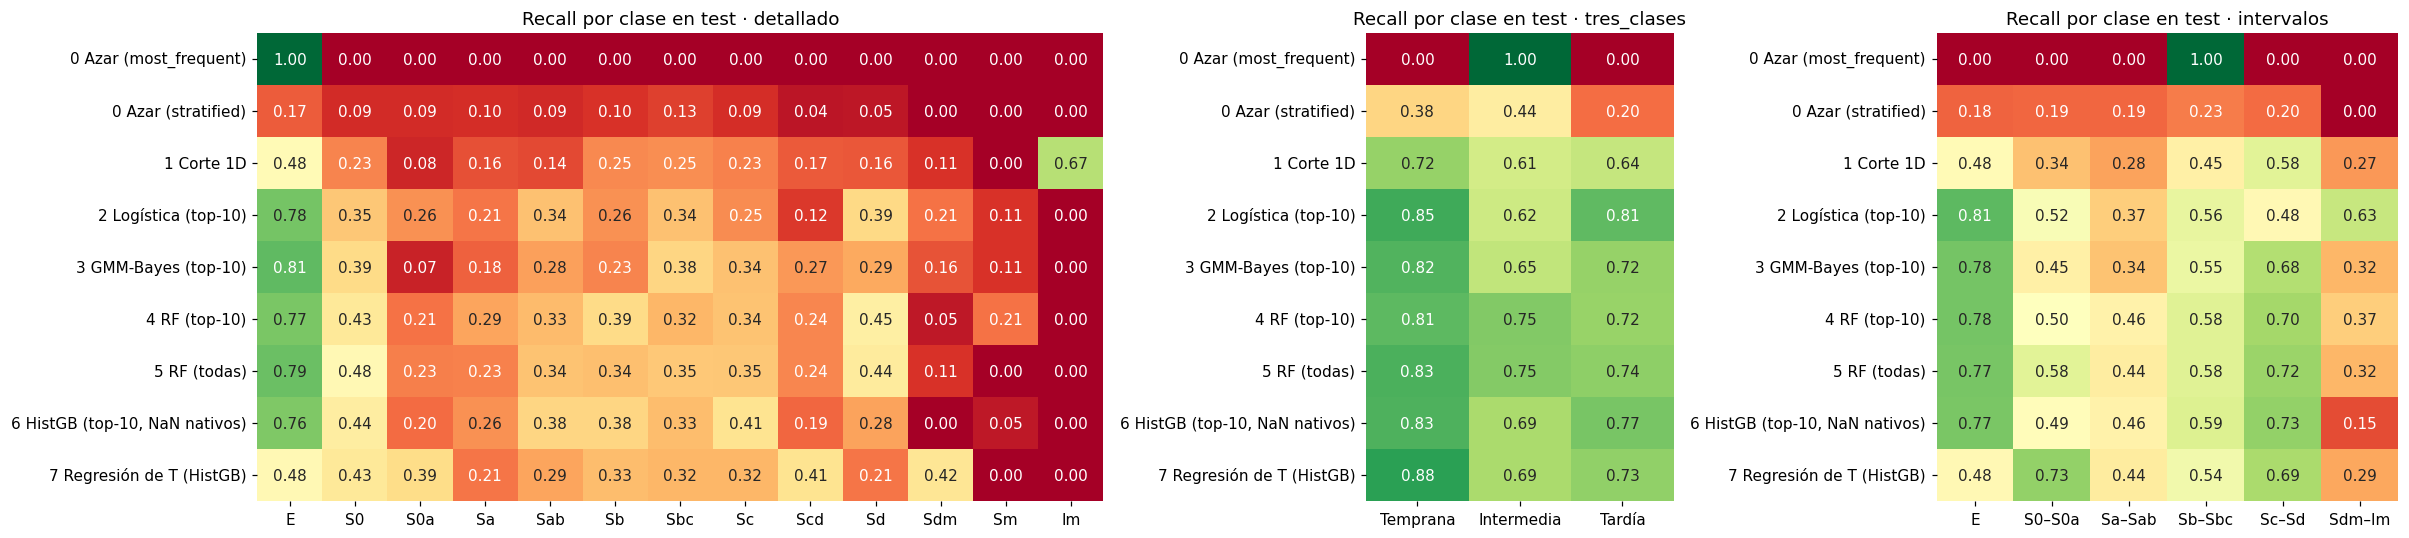

Galaxias por clase en test:
detallado {'E': 444, 'S0': 324, 'S0a': 152, 'Sa': 269, 'Sab': 261, 'Sb': 277, 'Sbc': 254, 'Sc': 253, 'Scd': 112, 'Sd': 85, 'Sdm': 19, 'Sm': 19, 'Im': 3}
tres_clases {'Temprana': 920, 'Intermedia': 1061, 'Tardía': 491}
intervalos {'E': 444, 'S0–S0a': 476, 'Sa–Sab': 530, 'Sb–Sbc': 531, 'Sc–Sd': 450, 'Sdm–Im': 41}


In [25]:
fig, axs = plt.subplots(1, 3, figsize=(22, 5), gridspec_kw={'width_ratios': [2.2, 0.8, 1.2]})
for ax, e in zip(axs, ESQUEMAS):
    y_te = df.loc[idx_test, f'y_{e}']
    recall = pd.DataFrame({nombre: recall_score(y_te, PRED_TEST[(nombre, esq)], labels=ORDEN_CLASES[e],
                                                average=None, zero_division=0)
                           for (nombre, esq) in PRED_TEST if esq == e}, index=ORDEN_CLASES[e]).T.sort_index()
    sns.heatmap(recall, annot=True, fmt='.2f', cmap='RdYlGn', vmin=0, vmax=1, ax=ax, cbar=False)
    ax.set_title(f'Recall por clase en test · {e}')
plt.tight_layout(); plt.show()
print('Galaxias por clase en test:')
for e in ESQUEMAS:
    print(e, df.loc[idx_test, f'y_{e}'].value_counts().reindex(ORDEN_CLASES[e]).to_dict())

**Conclusión 13.1 (esperada):**
* **E** y **Sc** suelen tener el mejor recall: son los extremos "puros" de la bimodalidad.
* **S0a, Sab y Scd** suelen tener el peor recall: son clases **intermedias** por definición, rodeadas de vecinos con los que los
  expertos también se confunden (Buta 2013).
* En **Sdm / Sm / Im**, el recall depende de pocas galaxias. Los modelos balanceados (logística, HistGB, RF + SMOTE) las recuperan
  mejor que GMM-Bayes, cuyo *prior* las castiga.
* El corte 1D tiende a acertar los extremos y a fallar todo lo intermedio: describe una **secuencia continua**, no tipos discretos.

## 13.2 Modelo recomendado
**Criterio:** el modelo **más simple** (el número más bajo de la escalera) cuya BA de **CV** esté a menos de 0.02 de la mejor.
Elegimos con CV, no con test, para que el test siga siendo un juicio independiente (principio de parsimonia).

Modelo recomendado por esquema: {'detallado': '2 Logística (top-10)', 'tres_clases': '2 Logística (top-10)', 'intervalos': '2 Logística (top-10)'}


,modelo,n_features,balanced_acc,mejora_sobre_azar,F1_macro,kappa_cuadratico,acierto_±1_clase,MAE_T,BA_ic95_bajo,BA_ic95_alto
esquema,,,,,,,,,,
detallado,2 Logística (top-10),10,0.277,0.216,0.263,0.786,0.690,1.630,0.257,0.303
tres_clases,2 Logística (top-10),10,0.760,0.640,0.741,0.769,0.996,1.781,0.742,0.776
intervalos,2 Logística (top-10),10,0.561,0.474,0.501,0.818,0.919,1.641,0.531,0.589


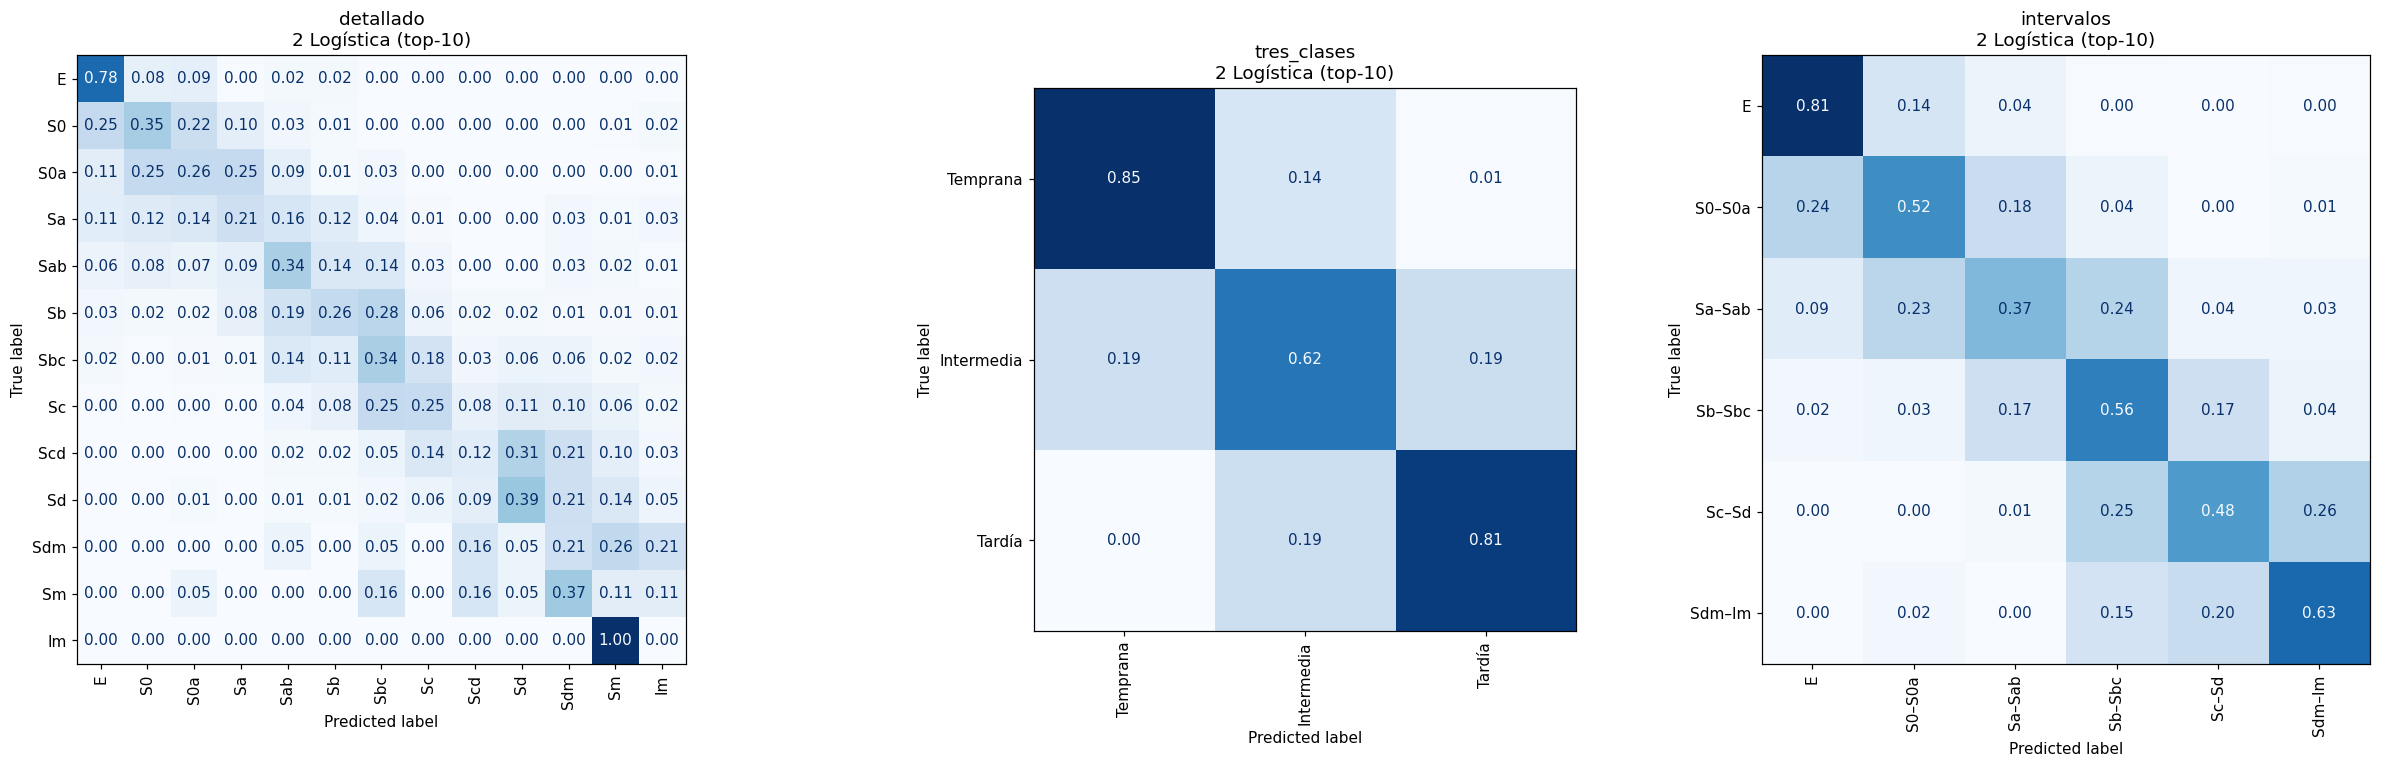

In [26]:
RECOMENDADO = {}
for e in ESQUEMAS:
    r = res[(res['esquema'] == e) & ~res['modelo'].str.startswith('0')]
    candidatos = r[r['balanced_acc'] >= r['balanced_acc'].max() - 0.02].sort_values('modelo')
    RECOMENDADO[e] = candidatos['modelo'].iloc[0]          # el primero = el más simple de la escalera
print('Modelo recomendado por esquema:', RECOMENDADO)
display(TEST[TEST.apply(lambda f: RECOMENDADO[f['esquema']] == f['modelo'], axis=1)].set_index('esquema'))

fig, axs = plt.subplots(1, 3, figsize=(24, 7), gridspec_kw={'width_ratios': [2, 1, 1.4]})
for ax, e in zip(axs, ESQUEMAS):
    ConfusionMatrixDisplay.from_predictions(df.loc[idx_test, f'y_{e}'], PRED_TEST[(RECOMENDADO[e], e)],
                                            labels=ORDEN_CLASES[e], normalize='true', values_format='.2f',
                                            cmap='Blues', colorbar=False, xticks_rotation=90, ax=ax)
    ax.set_title(f'{e}\n{RECOMENDADO[e]}')
plt.tight_layout(); plt.show()

**Conclusión 13.2:**
* En las matrices de confusión, la masa se concentra en la **diagonal y sus vecinas**: los errores son ordinales (κ ≈ 0.84), no
  aleatorios.
* Lo típico es confundir S0 ↔ S0a ↔ Sa, Sb ↔ Sbc ↔ Sc y Temprana ↔ Intermedia. Casi nunca se confunde E ↔ Sc.
* Si el recomendado en tres clases es la **logística** o el **corte 1D**, la conclusión física es fuerte: la clasificación gruesa
  está dominada por **una o pocas propiedades de la población estelar**.

## 13.3 Guardar los resultados
* Predicciones de test en **ECSV** (astropy): formato de texto con tipos y metadatos, legible en cualquier lenguaje. Lo usamos en
  lugar de FITS porque las etiquetas tienen acentos y guiones ("Tardía", "S0–S0a") que FITS no admite.
* Modelos en `joblib`.

In [27]:
salida = df.loc[idx_test, ['Ttype', 'y_detallado', 'y_tres_clases', 'y_intervalos']].copy()
salida['T_predicho_continuo'] = T_TEST
salida['T_predicho'] = T_TEST_VALIDO
for e in ESQUEMAS:
    salida[f'pred_{e}'] = PRED_TEST[(RECOMENDADO[e], e)]

tabla = Table.from_pandas(salida.reset_index())          # la columna 'name' (plate-ifu) queda como primera columna
tabla.meta.update({'descripcion': 'Predicciones del baseline morfológico MaNGA (test)',
                   'modelos': json.dumps(RECOMENDADO, ensure_ascii=False), 'semilla': SEMILLA})
tabla['T_predicho_continuo'].format = '.2f'
tabla.write(os.path.join(RUTA_BASE, 'predicciones_test.ecsv'), format='ascii.ecsv', overwrite=True)

TEST.to_csv(os.path.join(RUTA_BASE, 'resultados_test.csv'), index=False)
for e in ESQUEMAS:
    modelo, cols = MODELOS_FINALES.get((RECOMENDADO[e], e), (REG_T, cols_t))   # la regresión se guarda aparte
    joblib.dump({'modelo': modelo, 'columnas': cols}, os.path.join(RUTA_BASE, f'baseline_{e}.joblib'))
print('Guardado en', RUTA_BASE)

Guardado en /content/drive/MyDrive/Proyecto_morfologia/features_results/baseline


**Conclusión 13.3:**
* `predicciones_test.ecsv` se puede cruzar con el catálogo de morfología o con los mapas de MaNGA por `plateifu`, lo que facilita la
  inspección visual de los errores.
* Los `.joblib` guardan el modelo **y la lista de columnas** para aplicarlo a galaxias nuevas sin ambigüedad.

# 14. Análisis astrofísico de los errores (tres clases, RF top-10)
Un error del modelo puede ser **astrofísicamente interesante**:
* **Espirales pasivas o "rojas"** (Masters et al. 2010a): espirales sin formación estelar que el espectro ve como tempranas.
* **Tempranas azules** (Schawinski et al. 2009): E/S0 con formación estelar reciente que el espectro ve como tardías.
* **Espirales de canto con polvo** (Masters et al. 2010b): el polvo enrojece el espectro y simula una población vieja.

Comparamos las propiedades medianas de cada grupo "real → predicho".

,D4000n,HdA,log_EW_Ha,log_sSFR_Ha,log_NII_Ha,LogMass,log_Sigma90,b_a,SN_SL,n
grupo,,,,,,,,,,
Intermedia → Intermedia,1.39,2.36,1.02,-11.22,-0.36,10.21,7.76,0.52,32.71,801
Intermedia → Tardía,1.21,3.69,1.36,-10.77,-0.59,9.60,7.29,0.46,30.06,119
Intermedia → Temprana,1.78,-0.82,-0.10,-13.03,-0.05,10.43,7.90,0.61,29.76,141
Tardía → Intermedia,1.31,3.28,1.21,-11.04,-0.44,10.01,7.56,0.53,36.97,135
Tardía → Tardía,1.21,3.85,1.40,-10.80,-0.72,9.37,7.04,0.53,32.30,354
Tardía → Temprana,1.37,2.58,-0.07,-13.20,-0.61,9.65,7.00,0.69,20.48,2
Temprana → Intermedia,1.53,0.52,0.52,-11.88,-0.27,9.96,7.90,0.52,30.82,170
Temprana → Tardía,1.20,2.85,1.27,-10.90,-0.68,8.95,7.37,0.85,46.28,3
Temprana → Temprana,1.81,-1.21,-0.38,-13.73,-0.08,10.77,7.88,0.75,32.22,747


WHAN,Indeterminada,Pasiva,Retirada,SF,sAGN,wAGN
grupo,,,,,,
Intermedia → Intermedia,0.00,0.04,0.10,0.36,0.36,0.14
Intermedia → Tardía,0.01,0.00,0.00,0.90,0.08,0.01
Intermedia → Temprana,0.00,0.38,0.59,0.02,0.00,0.01
Tardía → Intermedia,0.00,0.02,0.03,0.69,0.24,0.01
Tardía → Tardía,0.01,0.00,0.00,0.95,0.02,0.02
Tardía → Temprana,0.00,0.50,0.00,0.50,0.00,0.00
Temprana → Intermedia,0.02,0.13,0.32,0.16,0.20,0.17
Temprana → Tardía,0.00,0.00,0.00,1.00,0.00,0.00
Temprana → Temprana,0.00,0.46,0.51,0.01,0.01,0.02


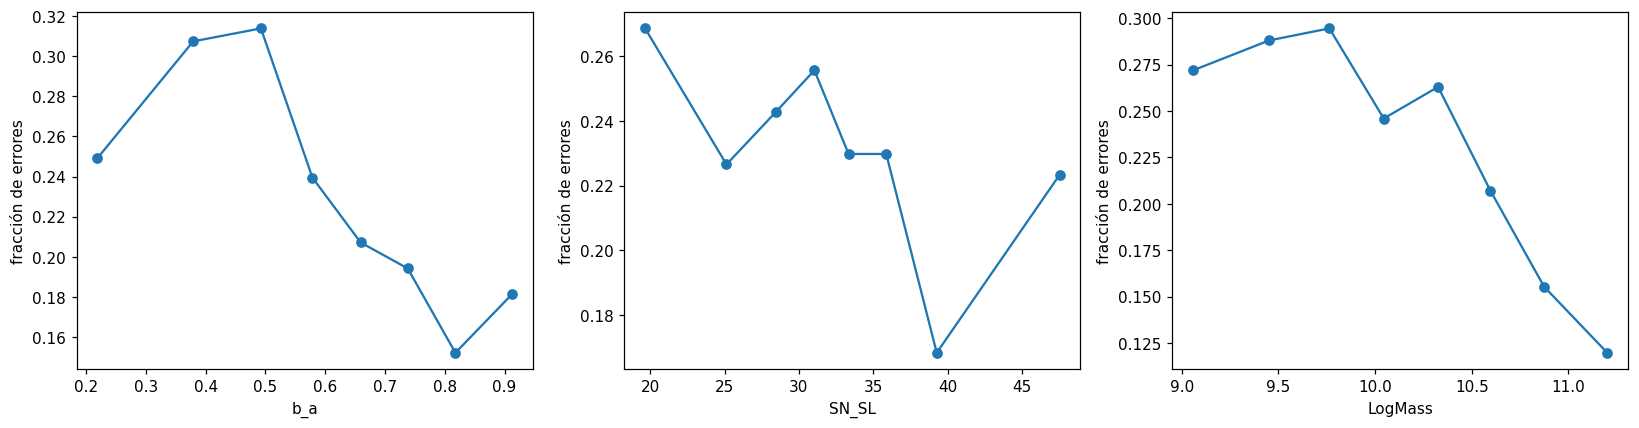

In [28]:
e = 'tres_clases'
err = df.loc[idx_test].copy()
err['pred'] = PRED_TEST[('4 RF (top-10)', e)]
err['grupo'] = err['y_tres_clases'] + ' → ' + err['pred']
err['error'] = err['y_tres_clases'] != err['pred']

props = existentes(['D4000n', 'HdA', 'log_EW_Ha', 'log_sSFR_Ha', 'log_NII_Ha', 'LogMass', 'log_Sigma90', 'b_a', 'SN_SL'])
mediana = err.groupby('grupo')[props].median().round(2)
display(mediana.join(err['grupo'].value_counts().rename('n')))
# Clase de actividad WHAN de cada grupo (Cid Fernandes et al. 2011)
display(pd.crosstab(err['grupo'], err['WHAN'], normalize='index').round(2))

# ¿Dónde se equivoca más el modelo? Tasa de error por cuantiles de inclinación, S/N y masa
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axs, existentes(['b_a', 'SN_SL', 'LogMass'])):
    tramos = pd.qcut(err[col], 8, duplicates='drop')
    ax.plot(err.groupby(tramos)[col].median(), err.groupby(tramos)['error'].mean(), 'o-')
    ax.set_xlabel(col); ax.set_ylabel('fracción de errores')
plt.tight_layout(); plt.show()

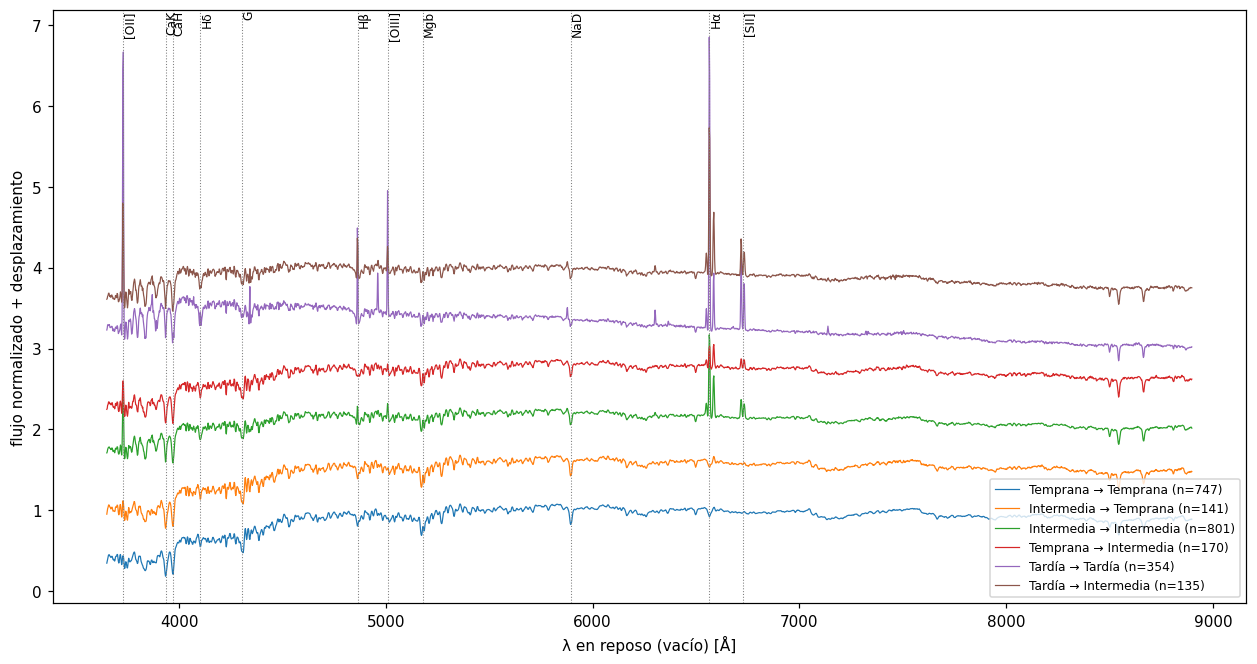

In [29]:
# Espectros medianos por grupo, en reposo y normalizados (la misma rejilla que FEatures)
LINEAS = {'[OII]': 3728, 'CaK': 3934, 'CaH': 3969, 'Hδ': 4103, 'G': 4305, 'Hβ': 4863,
          '[OIII]': 5008, 'Mgb': 5177, 'NaD': 5894, 'Hα': 6565, '[SII]': 6725}
GRUPOS = ['Temprana → Temprana', 'Intermedia → Temprana', 'Intermedia → Intermedia',
          'Temprana → Intermedia', 'Tardía → Tardía', 'Tardía → Intermedia']

fig, ax = plt.subplots(figsize=(14, 7))
for k, g in enumerate([g for g in GRUPOS if (err['grupo'] == g).sum() >= 5]):
    filas = df.index.get_indexer(err.index[err['grupo'] == g])        # filas de ESPECTROS
    ax.plot(GRID, np.nanmedian(ESPECTROS[filas], axis=0) + 0.6 * k, lw=0.8,
            label=f"{g} (n={len(filas)})")
for nombre, lam in LINEAS.items():
    ax.axvline(lam, color='gray', ls=':', lw=0.7)
    ax.text(lam, ax.get_ylim()[1], nombre, rotation=90, va='top', fontsize=8)
ax.set_xlabel('λ en reposo (vacío) [Å]'); ax.set_ylabel('flujo normalizado + desplazamiento')
ax.legend(loc='lower right', fontsize=8); plt.show()

**Conclusión 14 (esperada):**
* **Intermedia → Temprana:** D4000n alto, HδA bajo, EW(Hα) < 3 Å y WHAN mayoritariamente pasiva o retirada. Son **espirales
  pasivas**, frecuentes a masa alta (Masters et al. 2010a; Fraser-McKelvie et al. 2018). El espectro integrado **no puede ver los
  brazos**; el error es físico, no del modelo.
* **Temprana → Intermedia:** EW(Hα) y HδA más altos, con WHAN de formación estelar o AGN débil. Son **E/S0 rejuvenecidas** o con
  discos de gas (Schawinski et al. 2009; Kaviraj et al. 2007).
* Si la tasa de error **sube a b/a bajo** (galaxias de canto), el polvo enrojece las espirales y las acerca a las tempranas
  (Masters et al. 2010b).
* Si sube a **S/N bajo**, el problema es de medida, no de física.
* En los espectros medianos, los grupos mal clasificados se parecen más a su clase **predicha** que a su clase real. El clasificador
  es fiel al espectro: **el desacuerdo es morfología frente a población estelar**.

# 15. Ficha del baseline

In [30]:
FICHA = (TEST[TEST.apply(lambda f: RECOMENDADO[f['esquema']] == f['modelo'], axis=1)]
         .set_index('esquema').loc[ESQUEMAS, ['modelo', 'n_features', 'balanced_acc', 'BA_ic95_bajo', 'BA_ic95_alto',
                                              'mejora_sobre_azar', 'F1_macro', 'kappa_cuadratico', 'acierto_±1_clase', 'MAE_T']])
FICHA['azar'] = [1 / len(ORDEN_CLASES[e]) for e in ESQUEMAS]
FICHA['techo_σ1.3'] = [TECHO.loc[1.3, e] for e in ESQUEMAS]
FICHA['features'] = [', '.join(MODELOS_FINALES.get((RECOMENDADO[e], e), (None, cols_t))[1]) for e in ESQUEMAS]
display(FICHA.T)
FICHA.to_csv(os.path.join(RUTA_BASE, 'ficha_baseline.csv'))

esquema,detallado,tres_clases,intervalos
modelo,2 Logística (top-10),2 Logística (top-10),2 Logística (top-10)
n_features,10,10,10
balanced_acc,0.277,0.76,0.561
BA_ic95_bajo,0.257,0.742,0.531
BA_ic95_alto,0.303,0.776,0.589
mejora_sobre_azar,0.216,0.64,0.474
F1_macro,0.263,0.741,0.501
kappa_cuadratico,0.786,0.769,0.818
acierto_±1_clase,0.69,0.996,0.919
MAE_T,1.63,1.781,1.641


**Conclusión 15:**
La ficha es el **número a batir**: cualquier modelo futuro (CNN sobre imágenes, mapas IFU, espectros completos) debe superar la BA
del recomendado **fuera de su IC 95 %**. Además debe compararse con el **techo** de las etiquetas, no con 1.0.

# 16. Conclusiones generales
1. **La clasificación gruesa (tres clases) es fácil y casi lineal.**
   * BA ≈ 0.76 y κ ≈ 0.78.
   * Un corte en una sola propiedad (HδA, D4000n o EW(Hα)) recupera gran parte de la señal y redescubre D4000n ≈ 1.5
     (Kauffmann et al. 2003a).
   * La secuencia de Hubble, vista con un espectro integrado, es sobre todo la **bimodalidad edad / formación estelar**
     (Strateva et al. 2001; Baldry et al. 2004).
2. **La clasificación detallada está limitada por las etiquetas.**
   * BA ≈ 0.31, cerca del techo simulado con σ ≈ 1.3 T de ruido entre expertos (Naim et al. 1995).
   * Sin embargo, κ ≈ 0.84 y ±1 clase ≈ 0.74: los errores son de **vecindad**.
3. **Los intervalos son el compromiso**: BA ≈ 0.56, con buen κ y clases con significado físico.
4. **La complejidad aporta poco.** La logística, GMM-Bayes, RF y HistGB quedan a ≲ 0.03 entre sí. El límite es la **información**,
   no el algoritmo.
5. **Lo estructural no está en el espectro.**
   * E vs S0 depende de b/a, R90 y Σ*: geometría y compacidad (Cappellari et al. 2011).
   * Los brazos y las barras no se ven en un espectro integrado.
6. **Los errores tienen física**: espirales pasivas, tempranas azules y espirales de canto con polvo.
7. **Siguiente paso:** añadir información espacial, por ejemplo:
   * imágenes (Domínguez Sánchez et al. 2018, 2022);
   * gradientes radiales de edad / Hα a partir de los cubos MaNGA;
   * cinemática (λ_R; Emsellem et al. 2011).

# 17. Referencias
* Baldry, I. K. et al. 2004, ApJ 600, 681
* Blanton, M. R. & Moustakas, J. 2009, ARA&A 47, 159
* Breiman, L. 2001, Machine Learning 45, 5
* Brodersen, K. H. et al. 2010, ICPR, 3121
* Bundy, K. et al. 2010, ApJ 719, 1969; 2015, ApJ 798, 7 (MaNGA)
* Buta, R. J. 2013, in *Secular Evolution of Galaxies*, CUP, 155
* Cappellari, M. et al. 2011, MNRAS 416, 1680
* Chawla, N. V. et al. 2002, JAIR 16, 321
* Cid Fernandes, R. et al. 2005, MNRAS 358, 363 (STARLIGHT); 2011, MNRAS 413, 1687 (WHAN)
* Cohen, J. 1968, Psychological Bulletin 70, 213
* Connolly, A. J. et al. 1995, AJ 110, 1071
* de Vaucouleurs, G. 1959, Handbuch der Physik 53, 275
* de Vaucouleurs, G. et al. 1991, RC3, Springer
* Domínguez Sánchez, H. et al. 2018, MNRAS 476, 3661; 2022, MNRAS 509, 4024
* Efron, B. 1979, Ann. Stat. 7, 1
* Emsellem, E. et al. 2011, MNRAS 414, 888
* Fraser-McKelvie, A. et al. 2018, MNRAS 481, 5580
* Friedman, J. H. 2001, Ann. Stat. 29, 1189
* Huertas-Company, M. et al. 2011, A&A 525, A157
* Hubble, E. P. 1926, ApJ 64, 321; 1936, *The Realm of the Nebulae*
* Ivezić, Ž., Connolly, A., VanderPlas, J. & Gray, A. 2014, *Statistics, Data Mining and Machine Learning in Astronomy*, Princeton
  UP (astroML)
* Kauffmann, G. et al. 2003a, MNRAS 341, 33; 2003b, MNRAS 341, 54
* Kaviraj, S. et al. 2007, ApJS 173, 619
* Ke, G. et al. 2017, NeurIPS 30 (LightGBM)
* Kennicutt, R. C. 1998, ARA&A 36, 189
* Knuth, K. H. 2019, Digital Signal Processing 95, 102581
* Lahav, O. et al. 1995, Science 267, 859
* Lintott, C. et al. 2008, MNRAS 389, 1179; 2011, MNRAS 410, 166
* Masters, K. L. et al. 2010a, MNRAS 405, 783; 2010b, MNRAS 404, 792
* Naim, A. et al. 1995, MNRAS 274, 1107
* Nair, P. B. & Abraham, R. G. 2010, ApJS 186, 427
* Roberts, M. S. & Haynes, M. P. 1994, ARA&A 32, 115
* Sánchez Almeida, J. et al. 2010, ApJ 714, 487
* Sandage, A. 1961, *The Hubble Atlas of Galaxies*
* Schawinski, K. et al. 2009, MNRAS 396, 818; 2014, MNRAS 440, 889
* Shen, S. et al. 2003, MNRAS 343, 978
* Shimasaku, K. et al. 2001, AJ 122, 1238
* Strateva, I. et al. 2001, AJ 122, 1861
* van den Bergh, S. 1976, ApJ 206, 883
* VanderPlas, J. et al. 2012, CIDU, 47 (astroML)
* Vázquez-Mata, J. A. et al. 2022, MNRAS 512, 2222
* Yip, C. W. et al. 2004, AJ 128, 585